# Figure 4A–D: formal frozen ico5 analysis

This notebook reads cached full-cohort results and does not recompute profiles, geodesic neighbourhoods, real curves, null realizations, or boundary matches. Figure 4A–C use official ico5 anchors mapped one-to-one to fsaverage, within-DK-region candidates, nested sampling with $K=15$, and pair-sampling seed 0. The acquisition-and-sampling null uses 100 independently seeded realizations per subject. Figure 4D uses the same ico5 anchors and dense valid candidates, with deterministic one-to-one matching of within-region and across-boundary candidates from the same anchor at geodesic distances matched within 0.1 mm.

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/figure4_ico5_formal_k15')
PAIR_QC_DIR = ROOT / 'pair_qc'
REAL_DIR = ROOT / 'real' / 'cohort'
RELATIVE_MAE_DIR = ROOT / 'relative_mae' / 'cohort'
NULL_DIR = ROOT / 'acquisition_null_fwhm0_seedfix' / 'cohort'
CORRELATION_DIR = ROOT / 'correlation_length' / 'cohort'
BOUNDARY_DIR = ROOT / 'boundary_matched' / 'formal' / 'cohort'
COMPARISON_DIR = ROOT / 'comparison'

def show_image(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path)))

print(f'Frozen results: {ROOT}')

Frozen results: /mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/figure4_ico5_formal_k15


## Pair-table QC

Required checks are performed on the single frozen directed-pair list used by Figure 4A–C. The C split is fixed once within each hemisphere × DK-region stratum, and the same anchor remains in the same half across all distance bins.

In [2]:
pair_qc = json.loads((PAIR_QC_DIR / 'formal_pair_qc.json').read_text())
coverage = pd.read_csv(PAIR_QC_DIR / 'formal_k15_coverage_by_distance.csv')
display(pd.DataFrame([pair_qc]))
display(coverage)
assert pair_qc['status'] == 'pass'

,status,formal_pair_file,anchor_definition,candidate_definition,k,pair_seed,directed_pair_count,unique_anchor_count,split_seed,self_pair_count,...,directed_pair_repeated_across_bins_count,ico5_to_full_mapping_collision_count,full_to_ico5_mapping_collision_count,cross_region_pair_count,effective_k_mismatch_count,real_null_subjects_compared,real_null_count_mismatch_rows,real_null_curve_max_absolute_difference,split_assignment_anchor_count,split_assignment_max_stratum_count_difference
0,pass,/mnt/newStor/paros/paros_WORK/xintong/results/...,official_fsaverage5_fixed,within_DK_region,15,0,4182592,18742,20261021,0,...,0,0,0,0,0,325,0,0.000003,18742,1


,distance_bin_index,distance_bin,anchor_bins,k_effective_min,k_effective_q25,k_effective_median,k_effective_q75,k_effective_max,full_k15_fraction
0,0,0-2,18740,2,15.0,15.0,15.0,15,0.947866
1,1,2-4,18742,3,15.0,15.0,15.0,15,0.999413
2,2,4-6,18742,3,15.0,15.0,15.0,15,0.999253
3,3,6-8,18742,1,15.0,15.0,15.0,15,0.999627
4,4,8-10,18742,12,15.0,15.0,15.0,15,0.999893
5,5,10-12,18742,14,15.0,15.0,15.0,15,0.999947
6,6,12-14,18740,5,15.0,15.0,15.0,15,0.999787
7,7,14-16,18735,1,15.0,15.0,15.0,15,0.999680
8,8,16-18,18724,2,15.0,15.0,15.0,15,0.999306
9,9,18-20,18712,1,15.0,15.0,15.0,15,0.996900


## Figure 4A: real profile-shape dissimilarity

For every subject, pairwise $D=1-r$ and symmetric relative profile MAE are reduced as pair → anchor × 2-mm-bin median → bilateral subject median. Curves are group medians and bands are subject-level IQRs. Symmetric relative MAE is $200\,\mathrm{MAE}(x,y)/(\mathrm{median}|x|+\mathrm{median}|y|)$ and is reported as a percentage.

,distance_bin_index,distance_bin,pair_type,n_subjects,anchor_count_total,pair_count_total,profile_dissimilarity_median,profile_dissimilarity_q25,profile_dissimilarity_q75,profile_mae_median,profile_mae_q25,profile_mae_q75,profile_rmse_median,profile_rmse_q25,profile_rmse_q75,geodesic_distance_mm_median,geodesic_distance_mm_q25,geodesic_distance_mm_q75
0,0,0-2,within_region,325,5991701,88646502,0.052276,0.043284,0.064491,0.000076,0.000069,0.000083,0.000093,0.000085,0.000101,1.422338,1.422036,1.422563
1,1,2-4,within_region,325,5992282,89314595,0.098323,0.081126,0.120560,0.000113,0.000102,0.000125,0.000138,0.000125,0.000152,3.147476,3.147288,3.147708
2,2,4-6,within_region,325,5992242,89185568,0.120366,0.101588,0.146340,0.000131,0.000117,0.000146,0.000161,0.000144,0.000178,5.079590,5.079208,5.079758
3,3,6-8,within_region,325,5992199,89109529,0.132987,0.111134,0.159145,0.000140,0.000125,0.000156,0.000172,0.000154,0.000192,7.053471,7.053236,7.053753
4,4,8-10,within_region,325,5992164,89050837,0.139327,0.117102,0.166560,0.000145,0.000129,0.000161,0.000178,0.000158,0.000198,9.040245,9.039752,9.040535
5,5,10-12,within_region,325,5992107,89001608,0.143233,0.119450,0.171273,0.000147,0.000132,0.000164,0.000182,0.000162,0.000202,11.031494,11.031004,11.031914
6,6,12-14,within_region,325,5991424,88935851,0.145022,0.121396,0.172294,0.000149,0.000133,0.000167,0.000183,0.000163,0.000204,13.018652,13.018354,13.018994
7,7,14-16,within_region,325,5989730,88845326,0.146050,0.121961,0.173798,0.000150,0.000134,0.000168,0.000185,0.000166,0.000207,15.013445,15.013105,15.013646
8,8,16-18,within_region,325,5986224,88773552,0.147498,0.123566,0.176898,0.000151,0.000135,0.000170,0.000187,0.000167,0.000208,17.006516,17.006355,17.006855
9,9,18-20,within_region,325,5982029,88555127,0.148253,0.123953,0.176990,0.000153,0.000136,0.000172,0.000188,0.000168,0.000210,19.003262,19.003040,19.003582


,distance_bin_index,distance_bin,distance_bin_center_mm,n_subjects,median,q25,q75,bootstrap_ci95_low,bootstrap_ci95_high,anchor_count_total,pair_count_total
0,0,0-2,1,325,10.316460,9.401500,11.046659,10.144024,10.489102,5991701,88646502
1,1,2-4,3,325,15.441720,14.000859,16.813330,15.184233,15.723888,5992282,89314595
2,2,4-6,5,325,18.032972,16.254328,19.720644,17.636147,18.361568,5992242,89185568
3,3,6-8,7,325,19.234259,17.347492,21.231075,18.906380,19.668291,5992199,89109529
4,4,8-10,9,325,19.937902,17.895775,21.996954,19.552063,20.233065,5992164,89050837
5,5,10-12,11,325,20.266247,18.241170,22.453457,19.904198,20.588858,5992107,89001608
6,6,12-14,13,325,20.584948,18.458218,22.748886,20.170094,20.826435,5991424,88935851
7,7,14-16,15,325,20.721287,18.603964,22.961199,20.404099,21.057604,5989730,88845326
8,8,16-18,17,325,20.896801,18.793333,23.173481,20.597343,21.205912,5986224,88773552
9,9,18-20,19,325,20.985035,18.901390,23.307652,20.677776,21.374163,5982029,88555127


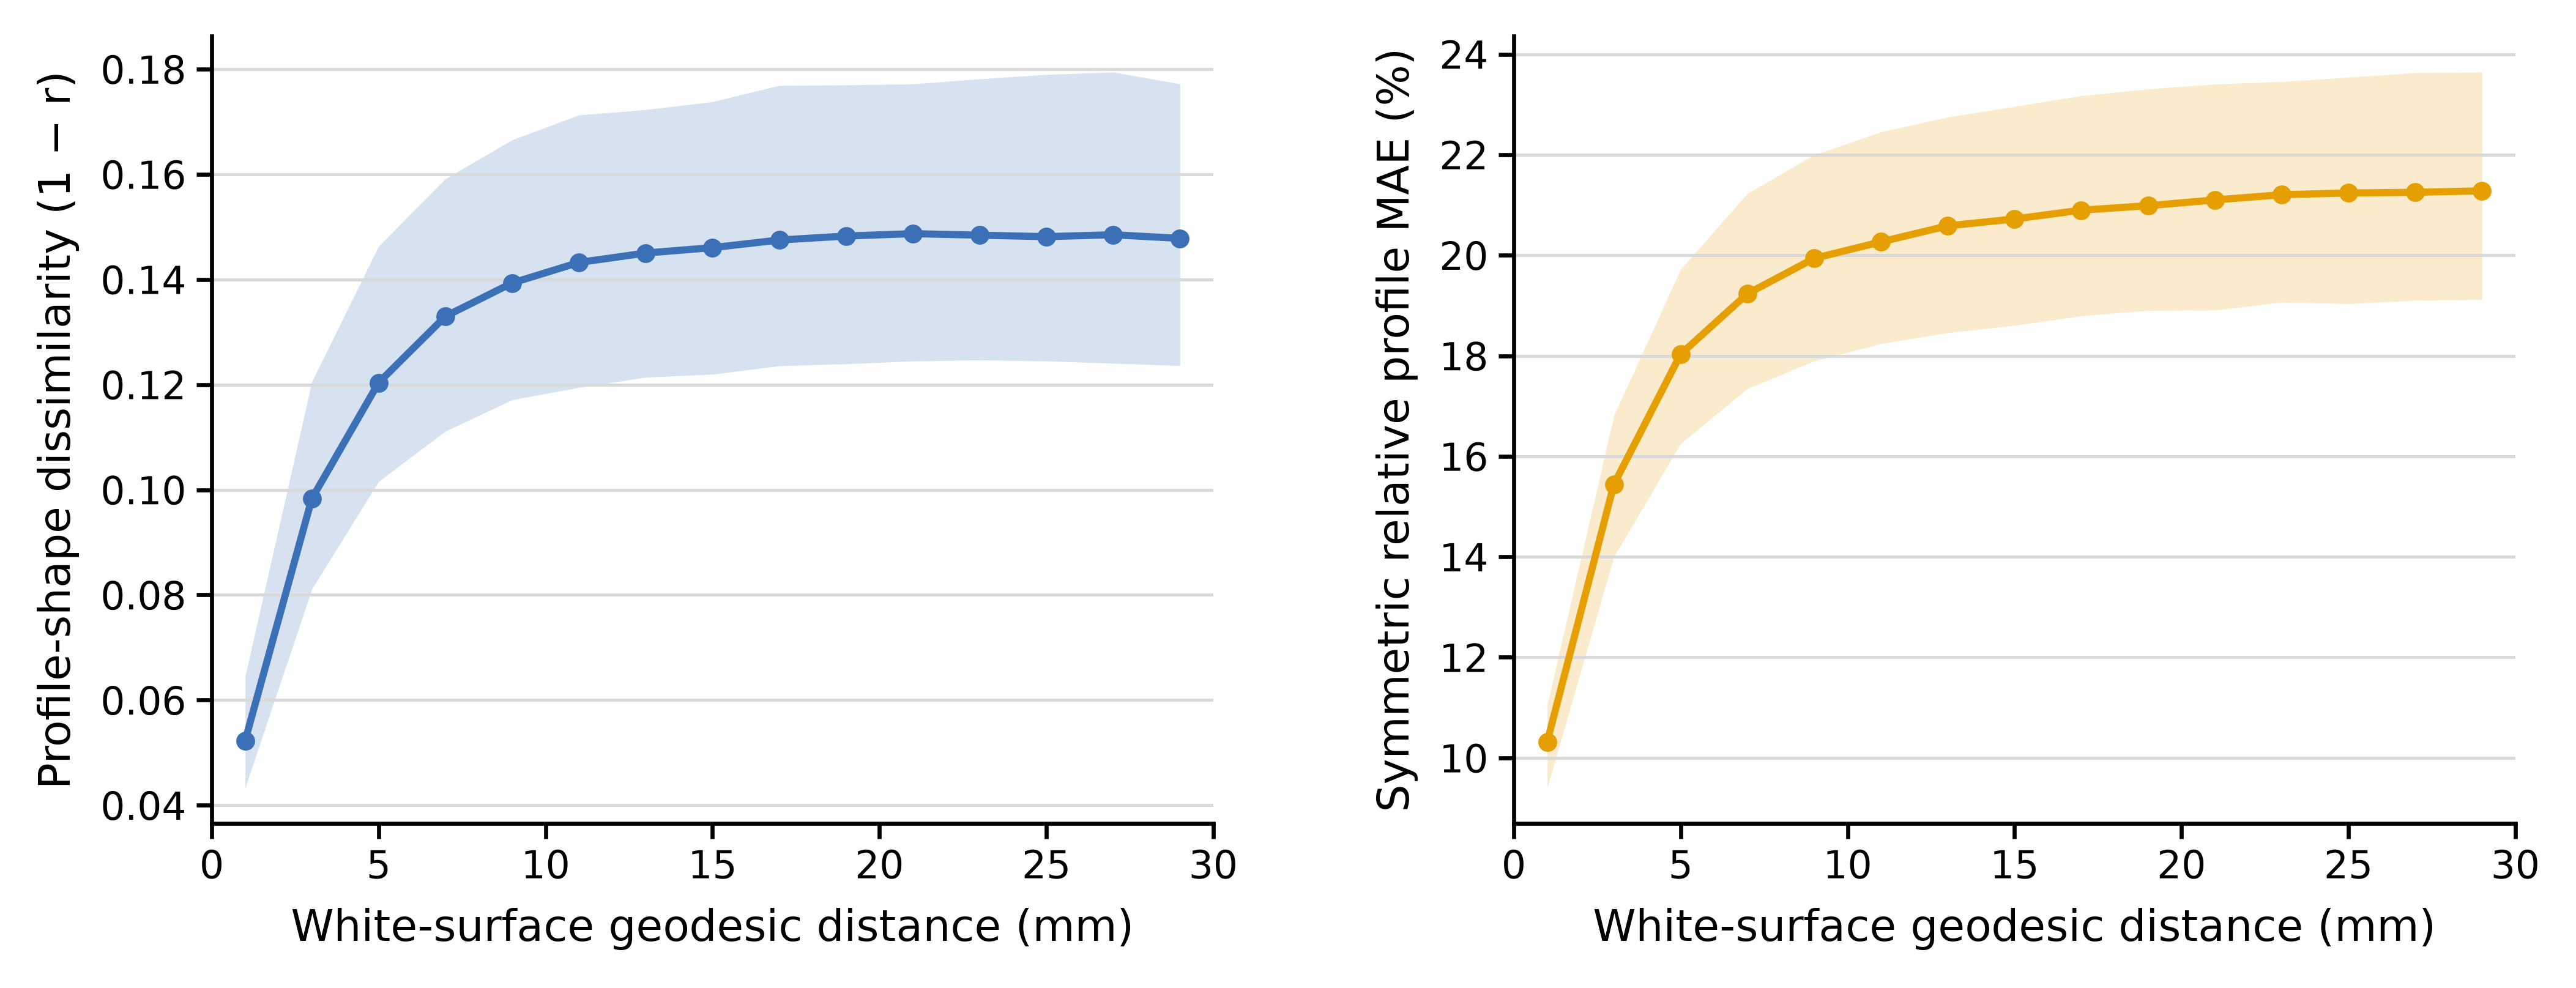

In [3]:
real_group = pd.read_csv(REAL_DIR / 'figure4A_ico5_k15_real_group_summary.csv')
relative_mae_group = pd.read_csv(
    RELATIVE_MAE_DIR / 'figure4_relative_mae_group_summary.csv'
)
display(real_group)
display(relative_mae_group)
show_image(REAL_DIR / 'Figure4A_ico5_K15_with_relative_MAE.png')

## Figure 4B: seed-fixed acquisition-and-sampling null

The null is Gaussian noise on each subject's native DWI grid, sampled through the real O3 coordinates with trilinear interpolation and recolored to match the subject-specific laminar mean and 21×21 depth covariance. The primary plateau is 20–30 mm. The main result is the residual local-excess similarity $L_{real}(d)-L_{null}(d)$; it is not interpreted as a purely physiological effect.

,subjects_expected,subjects_completed_per_condition,all_expected_subjects_complete,realizations_per_subject,psf_fwhm_mm,count_mismatch_rows,all_masks_identical,all_curve_values_finite,maximum_depth_mean_mae,maximum_depth_sd_mae,...,unique_subject_seeds,subject_seed_collision_count,unique_subject_realization_seeds,subject_realization_seed_collision_count,far_window_sensitivity_windows,real_curve_consistent_across_psf,anchor_and_pair_counts_consistent_across_psf,random_field_support,sampling_coordinates,status
0,325,{'0.0': 325},True,100,[0.0],0,True,True,8.198805e-09,3.852833e-09,...,325,0,32500,0,"{'10-20_mm': [5, 9], '16-30_mm': [8, 14], '20-...",True,True,[complete_native_dwi_fov],[real_o3_dwi_voxel_coordinates],full_cohort_complete


,psf_fwhm_mm,n_subjects,bootstrap_replicates,bootstrap_seed,auc_residual_local_excess_0_10_mm_median,auc_residual_local_excess_0_10_mm_q25,auc_residual_local_excess_0_10_mm_q75,auc_residual_local_excess_0_10_mm_bootstrap_ci_low,auc_residual_local_excess_0_10_mm_bootstrap_ci_high,auc_residual_local_excess_0_10_mm_positive_fraction,mean_residual_local_excess_0_10_median,mean_residual_local_excess_0_10_q25,mean_residual_local_excess_0_10_q75,mean_residual_local_excess_0_10_bootstrap_ci_low,mean_residual_local_excess_0_10_bootstrap_ci_high,mean_residual_local_excess_0_10_positive_fraction
0,0.0,325,10000,20261020,0.356685,0.306387,0.429263,0.348123,0.368981,1.0,0.035669,0.030639,0.042926,0.034911,0.036855,1.0


,psf_fwhm_mm,far_window,n_subjects,median,q25,q75,positive_fraction
0,0.0,10-20_mm,325,0.329166,0.280976,0.394152,1.0
1,0.0,16-30_mm,325,0.352411,0.302786,0.423514,1.0
2,0.0,20-30_mm_primary,325,0.357503,0.305615,0.430390,1.0
3,0.0,24-30_mm,325,0.358166,0.309287,0.432521,1.0


,psf_fwhm_mm,from_realizations,to_realizations,metric,median_absolute_change,maximum_absolute_change
0,0.0,5,10,null_dissimilarity_median,0.000210,0.000605
1,0.0,5,10,null_minus_real_median,0.000209,0.000559
2,0.0,10,20,null_dissimilarity_median,0.000128,0.000661
3,0.0,10,20,null_minus_real_median,0.000114,0.000363
4,0.0,20,50,null_dissimilarity_median,0.000186,0.000583
5,0.0,20,50,null_minus_real_median,0.000075,0.000289
6,0.0,50,100,null_dissimilarity_median,0.000097,0.000456
7,0.0,50,100,null_minus_real_median,0.000127,0.000282


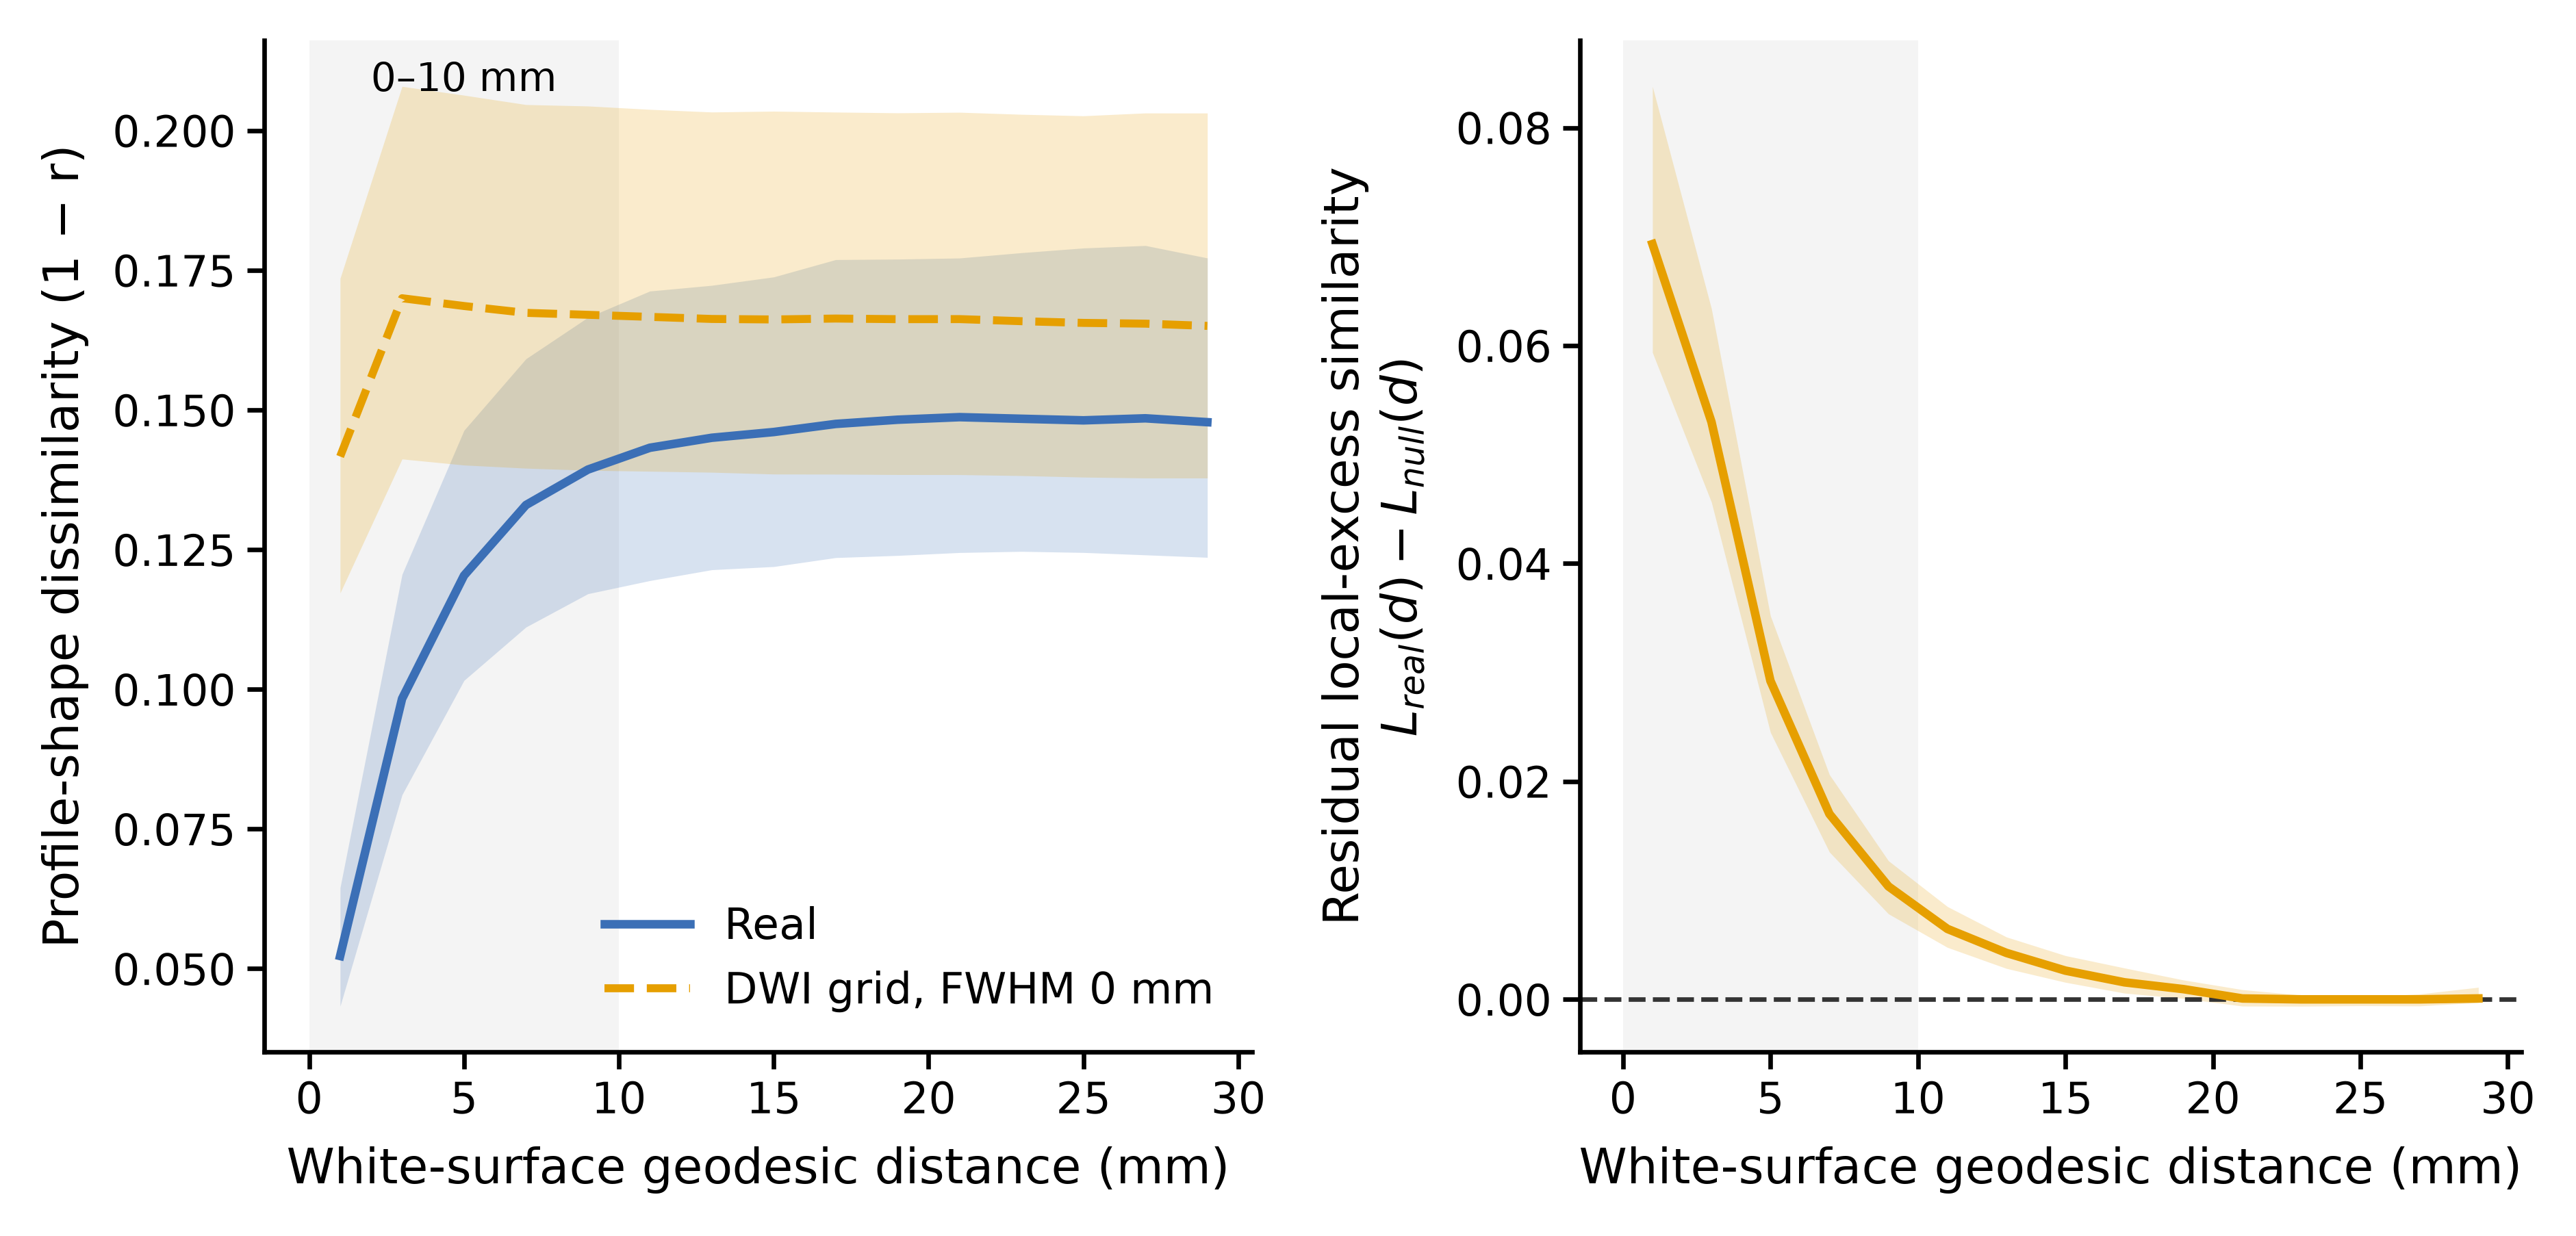

In [ ]:
null_validation = json.loads((NULL_DIR / 'figure4B_acquisition_validation_summary.json').read_text())
auc_group = pd.read_csv(NULL_DIR / 'figure4B_local_excess_auc_group_summary.csv')
far_windows = pd.read_csv(NULL_DIR / 'figure4B_far_window_sensitivity_auc_group.csv')
convergence = pd.read_csv(NULL_DIR / 'figure4B_acquisition_convergence.csv')
display(pd.DataFrame([null_validation]))ß
display(auc_group)
display(far_windows)
display(convergence)
show_image(NULL_DIR / 'Figure4B_ico5_K15_formal_main.png')

### Figure 4B supplementary subject-level AUC

Each point is one subject's 0–10-mm residual local-excess AUC; the horizontal line and vertical segment show the median and IQR.

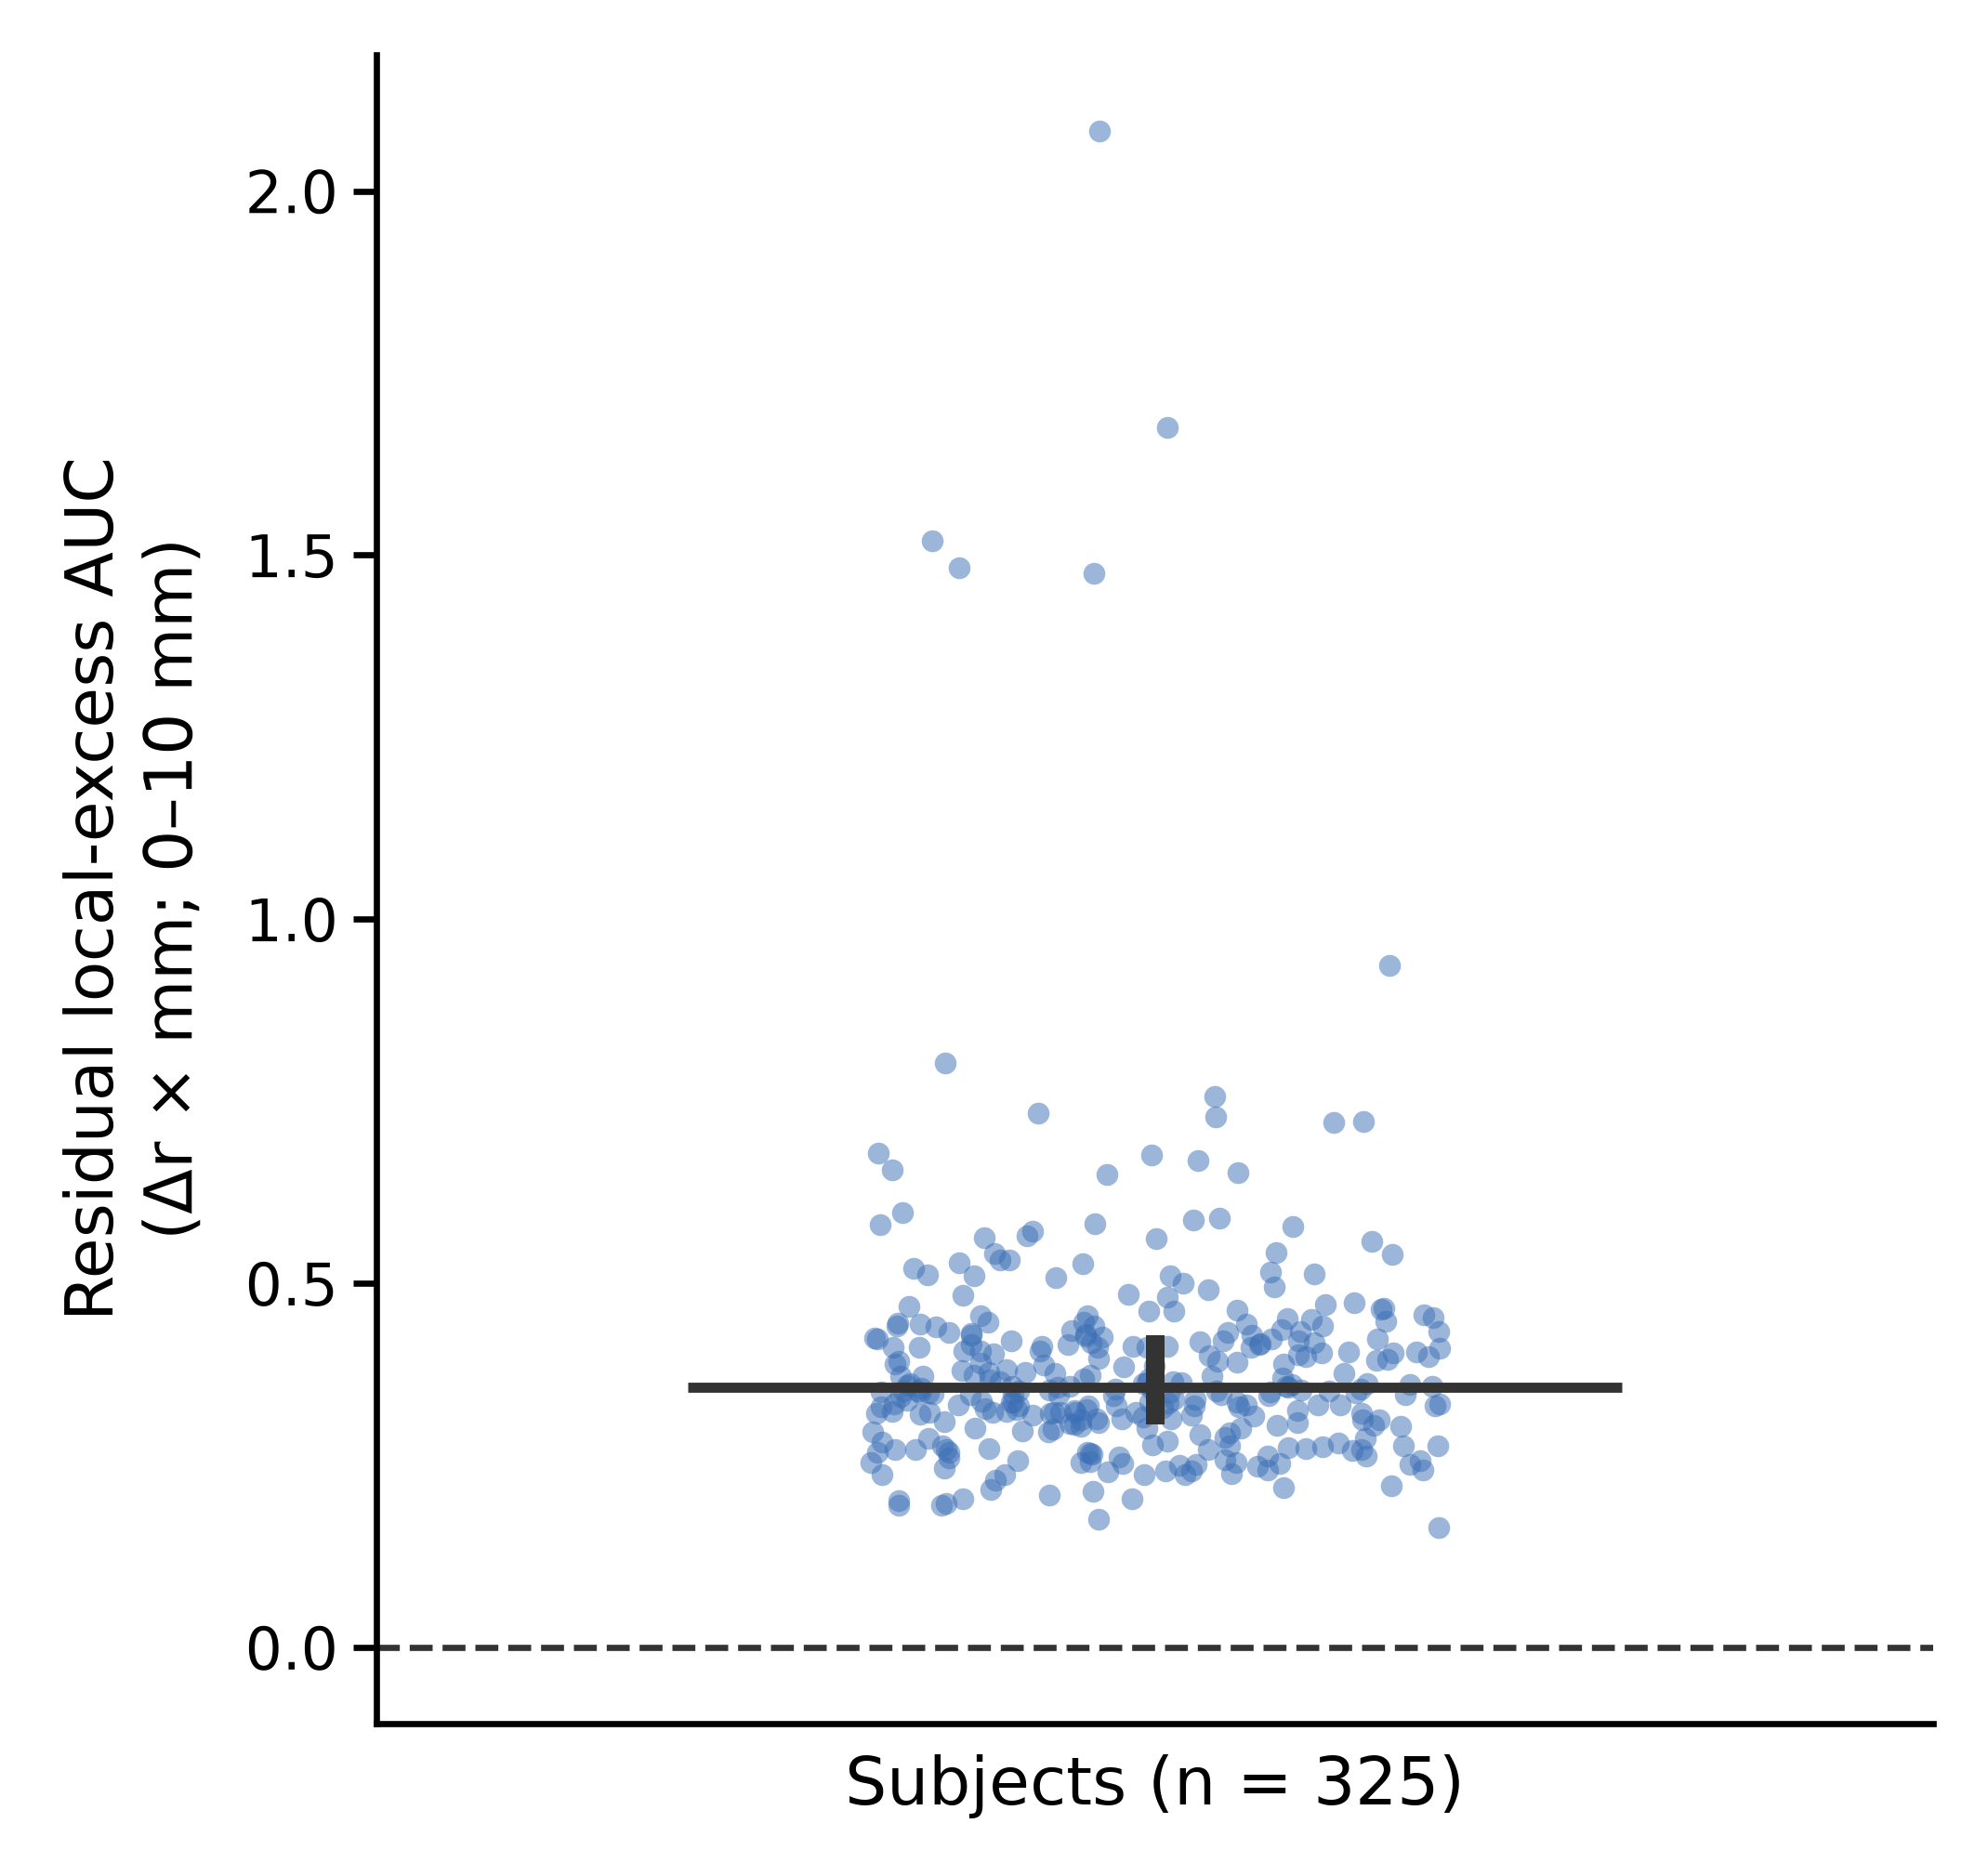

In [5]:
show_image(NULL_DIR / 'Figure4B_ico5_K15_AUC_supplement.png')

## Figure 4C: correlation length and split-half reproducibility

The exponential model is $D(d)=D_\infty-A\exp(-d/\lambda)$. Full-data and fixed stratified half-curves use the same fitting bounds and acceptance criterion ($R^2\geq0.5$ with no parameter-boundary hit).

,n_subjects,lambda_median_mm,lambda_q25_mm,lambda_q75_mm,d_infinity_median,amplitude_median,r2_median
0,325,2.85848,2.667693,3.041678,0.147804,0.152239,0.996628


,n_subjects_total,n_paired_acceptable,pearson_r,spearman_rho,icc_two_way_single,median_absolute_difference_mm,n_failed_or_unacceptable_subjects
0,325,324,0.896386,0.858713,0.896382,0.102957,1


,fit_scope,n_fits,n_success,n_acceptable,n_boundary,median_r2,median_residual_rmse
0,fixed_half_1,325,325,324,1,0.995916,0.001644
1,fixed_half_2,325,325,325,0,0.995015,0.001824
2,full,325,325,325,0,0.996628,0.001487


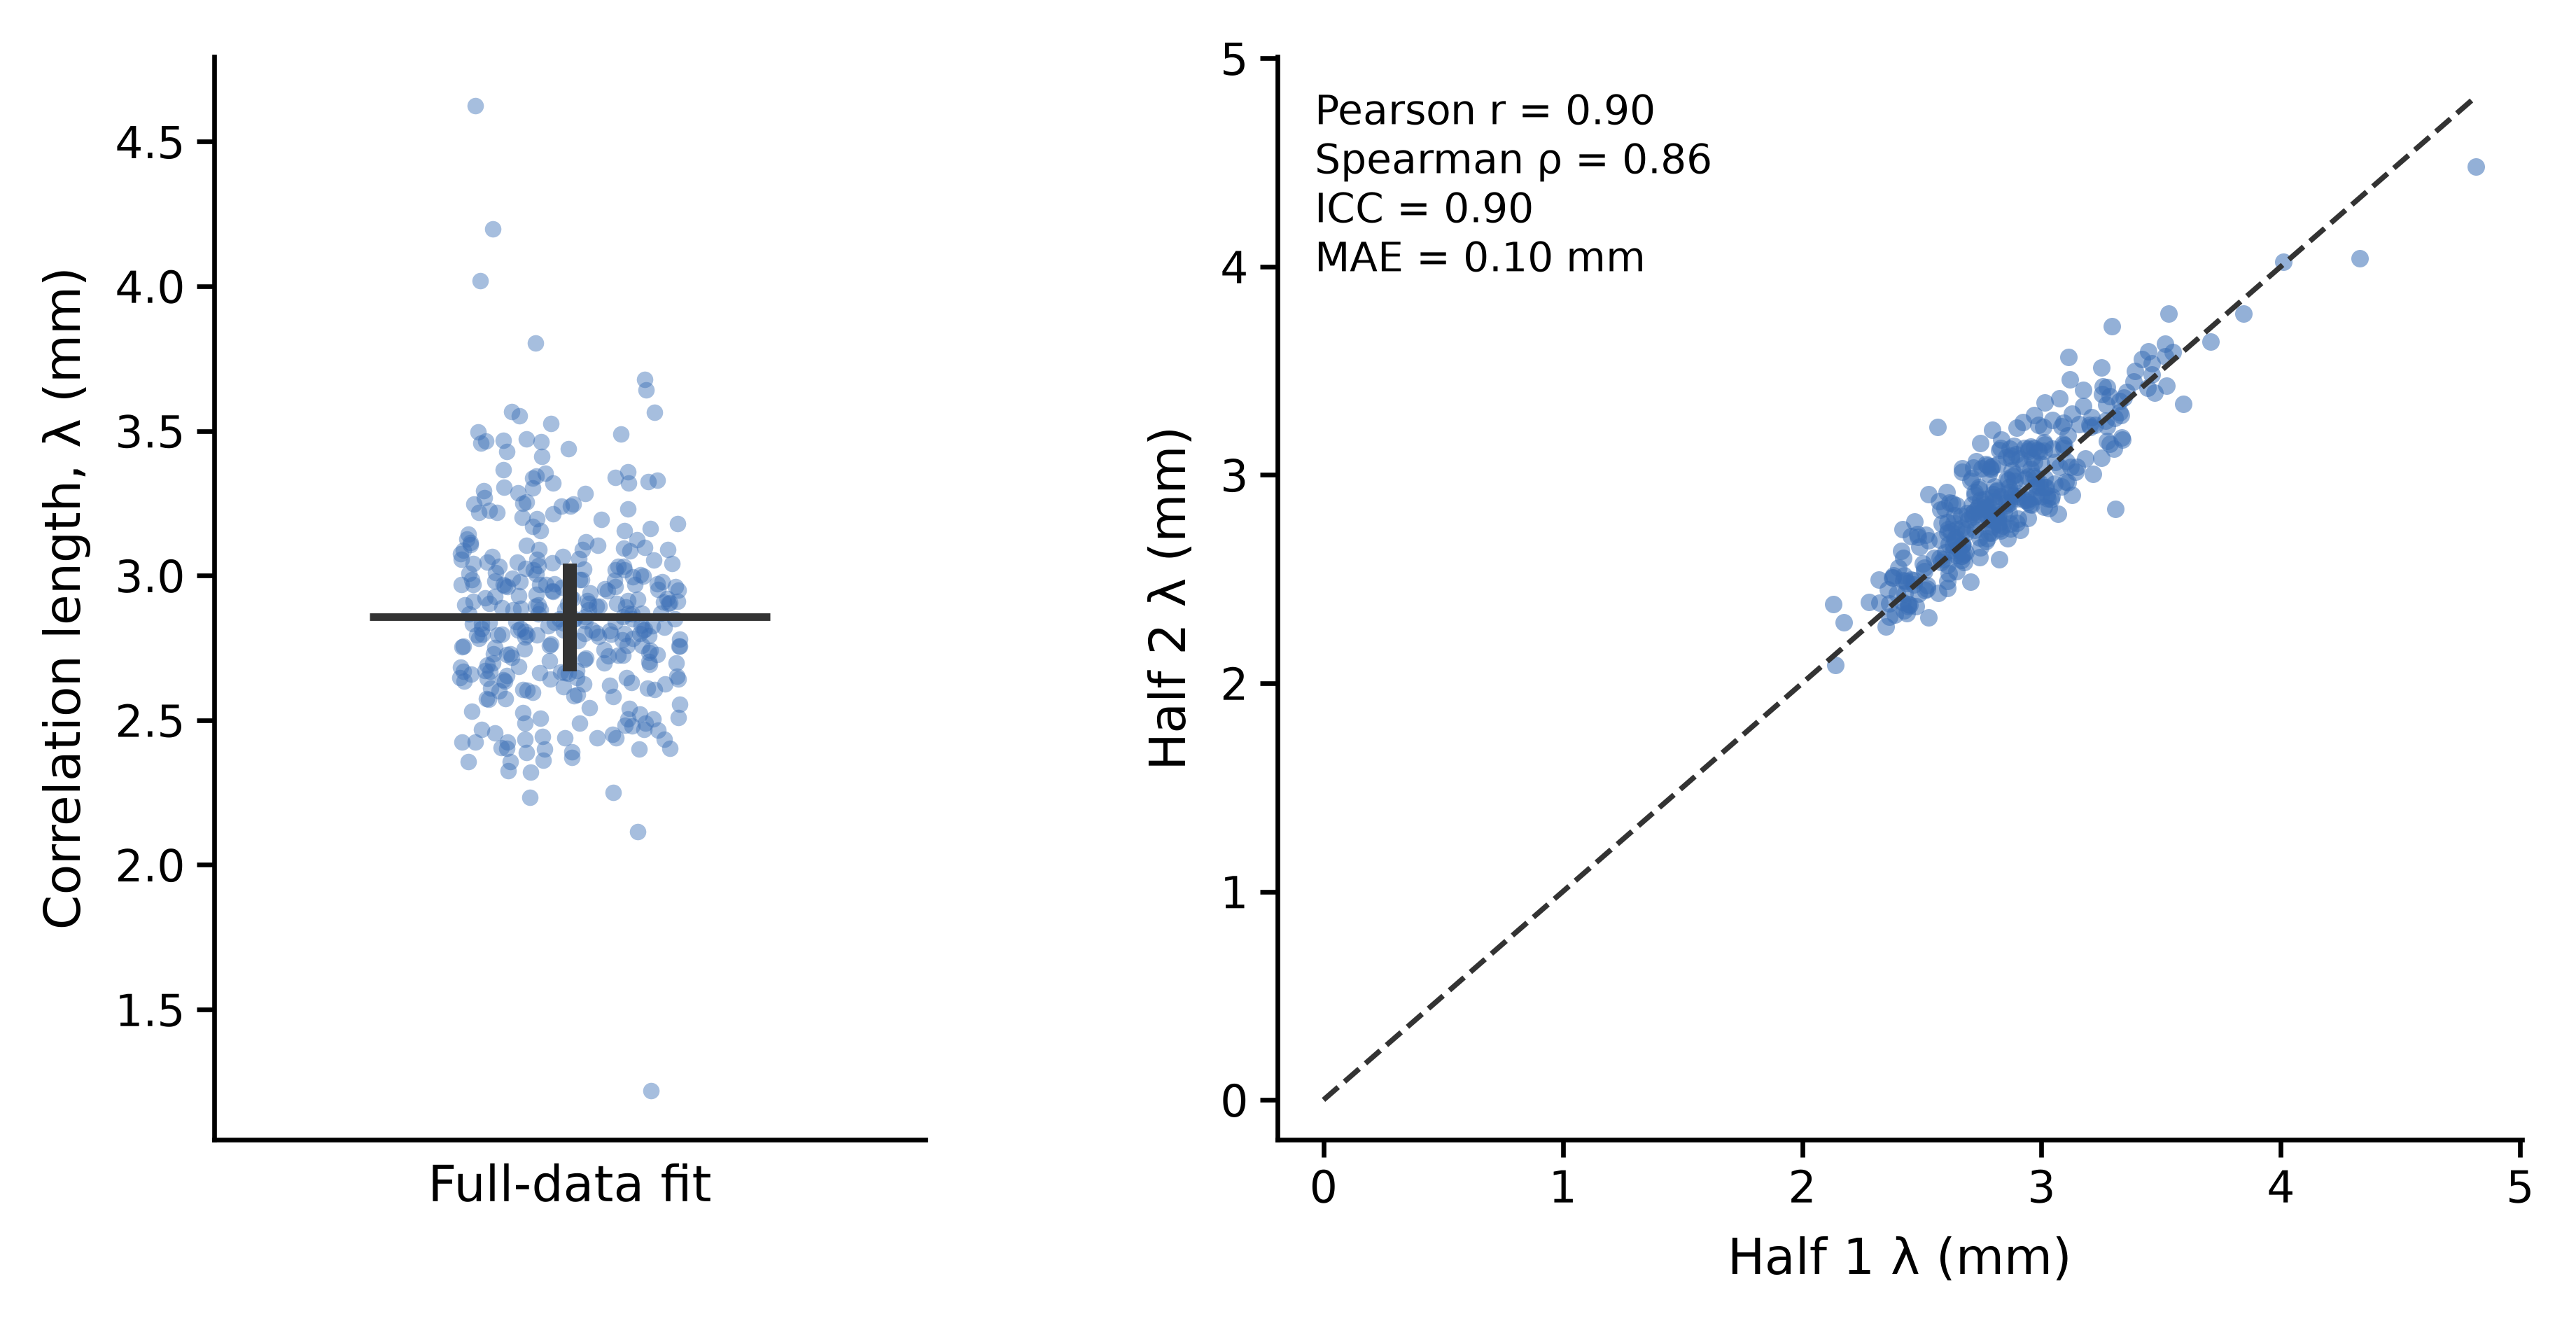

In [6]:
full_fit = pd.read_csv(CORRELATION_DIR / 'figure4C_full_fit_summary.csv')
reliability = pd.read_csv(CORRELATION_DIR / 'figure4C_fixed_split_reliability.csv')
fit_qc = pd.read_csv(CORRELATION_DIR / 'figure4C_fit_qc_summary.csv')
display(full_fit)
display(reliability)
display(fit_qc)
show_image(CORRELATION_DIR / 'Figure4C_ico5_K15_correlation_length.png')

## Figure 4D: within-region versus across-boundary matched pairs

For each subject, hemisphere, ico5 anchor, and 2-mm distance bin from 0–10 mm, within-region and across-boundary candidates are deterministically matched one-to-one by white-surface geodesic distance (maximum mismatch 0.1 mm; up to 15 matches). The displayed effect is $\Delta D=D_{across}-D_{within}$ after matched pairs → anchor-bin mean → bilateral subject-region-bin mean → equal-region subject-bin mean. The curve is the group median with subject-level IQR; positive values indicate greater across-boundary profile-shape dissimilarity.

,status,subjects,self_pairs,duplicate_rows,within_candidate_duplicates_within_anchor_bin,across_candidate_duplicates_within_anchor_bin,duplicate_directed_pairs,cross_bin_duplicates,within_label_violations,across_label_violations,maximum_distance_difference_mm,caliper_mm,reciprocal_pair_count_total
0,pass,325,0,0,0,0,0,0,0,0,0.099999,0.1,2041576


,distance_bin_index,distance_bin,n_subjects,delta_d_median,delta_d_q25,delta_d_q75,d_within_median,d_across_median,delta_profile_mae_median,region_count_median_subject,anchor_count_median_subject,match_count_median_subject
0,0,0-2,325,0.002364,-0.003714,0.006664,0.270068,0.271074,1.648788e-06,34.0,2909.0,17589.0
1,1,2-4,325,-0.000299,-0.004529,0.004202,0.376888,0.374172,1.779421e-06,34.0,5973.0,70284.0
2,2,4-6,325,-0.002133,-0.006923,0.002950,0.423616,0.418472,1.644982e-06,34.0,8601.0,113935.0
3,3,6-8,325,-0.004515,-0.009533,0.000554,0.448349,0.442447,1.092686e-06,34.0,10908.0,151170.0
4,4,8-10,325,-0.005592,-0.011021,-0.001071,0.461888,0.453821,6.424339e-07,34.0,12828.0,182734.0


,n_subjects,median_mean_delta_d_0_10,q25_mean_delta_d_0_10,q75_mean_delta_d_0_10,bootstrap_ci95_low,bootstrap_ci95_high,positive_subject_count,positive_subject_fraction,bootstrap_seed,bootstrap_iterations
0,325,-0.002409,-0.005988,0.001432,-0.00302,-0.001659,113,0.347692,20261027,10000


,distance_bin_index,distance_bin,n_subjects,matched_pair_rows_total,matched_anchor_count_total,matched_anchor_count_median_subject,valid_anchor_dk_regions_median_subject,n_matched_median_of_subject_medians,n_matched_q25_median_subject,n_matched_q75_median_subject,full_k15_anchor_coverage,distance_mismatch_median_mm_median_subject,distance_mismatch_q95_mm_max_subject,distance_mismatch_maximum_mm,within_distance_median_mm_median_subject,within_distance_q25_mm_median_subject,within_distance_q75_mm_median_subject,across_distance_median_mm_median_subject,across_distance_q25_mm_median_subject,across_distance_q75_mm_median_subject
0,0,0-2,325,5682054,939867,2909.0,34.0,5.0,3.0,9.0,0.041846,0.018857,0.081729,0.099994,1.567338,1.241675,1.804071,1.567212,1.241824,1.802209
1,1,2-4,325,22700428,1929700,5973.0,34.0,15.0,9.0,15.0,0.613711,0.005751,0.058759,0.099997,3.379362,2.908058,3.721274,3.379277,2.908959,3.721851
2,2,4-6,325,36798763,2778128,8601.0,34.0,15.0,15.0,15.0,0.796089,0.002141,0.043990,0.099988,5.285947,4.773582,5.675056,5.286098,4.773583,5.675032
3,3,6-8,325,48819154,3523688,10908.0,34.0,15.0,15.0,15.0,0.867285,0.001075,0.036358,0.099933,7.228445,6.702594,7.645001,7.228405,6.702578,7.644702
4,4,8-10,325,59020780,4143872,12828.0,34.0,15.0,15.0,15.0,0.912901,0.000632,0.029960,0.099999,9.187122,8.658360,9.623939,9.187232,8.658450,9.624009


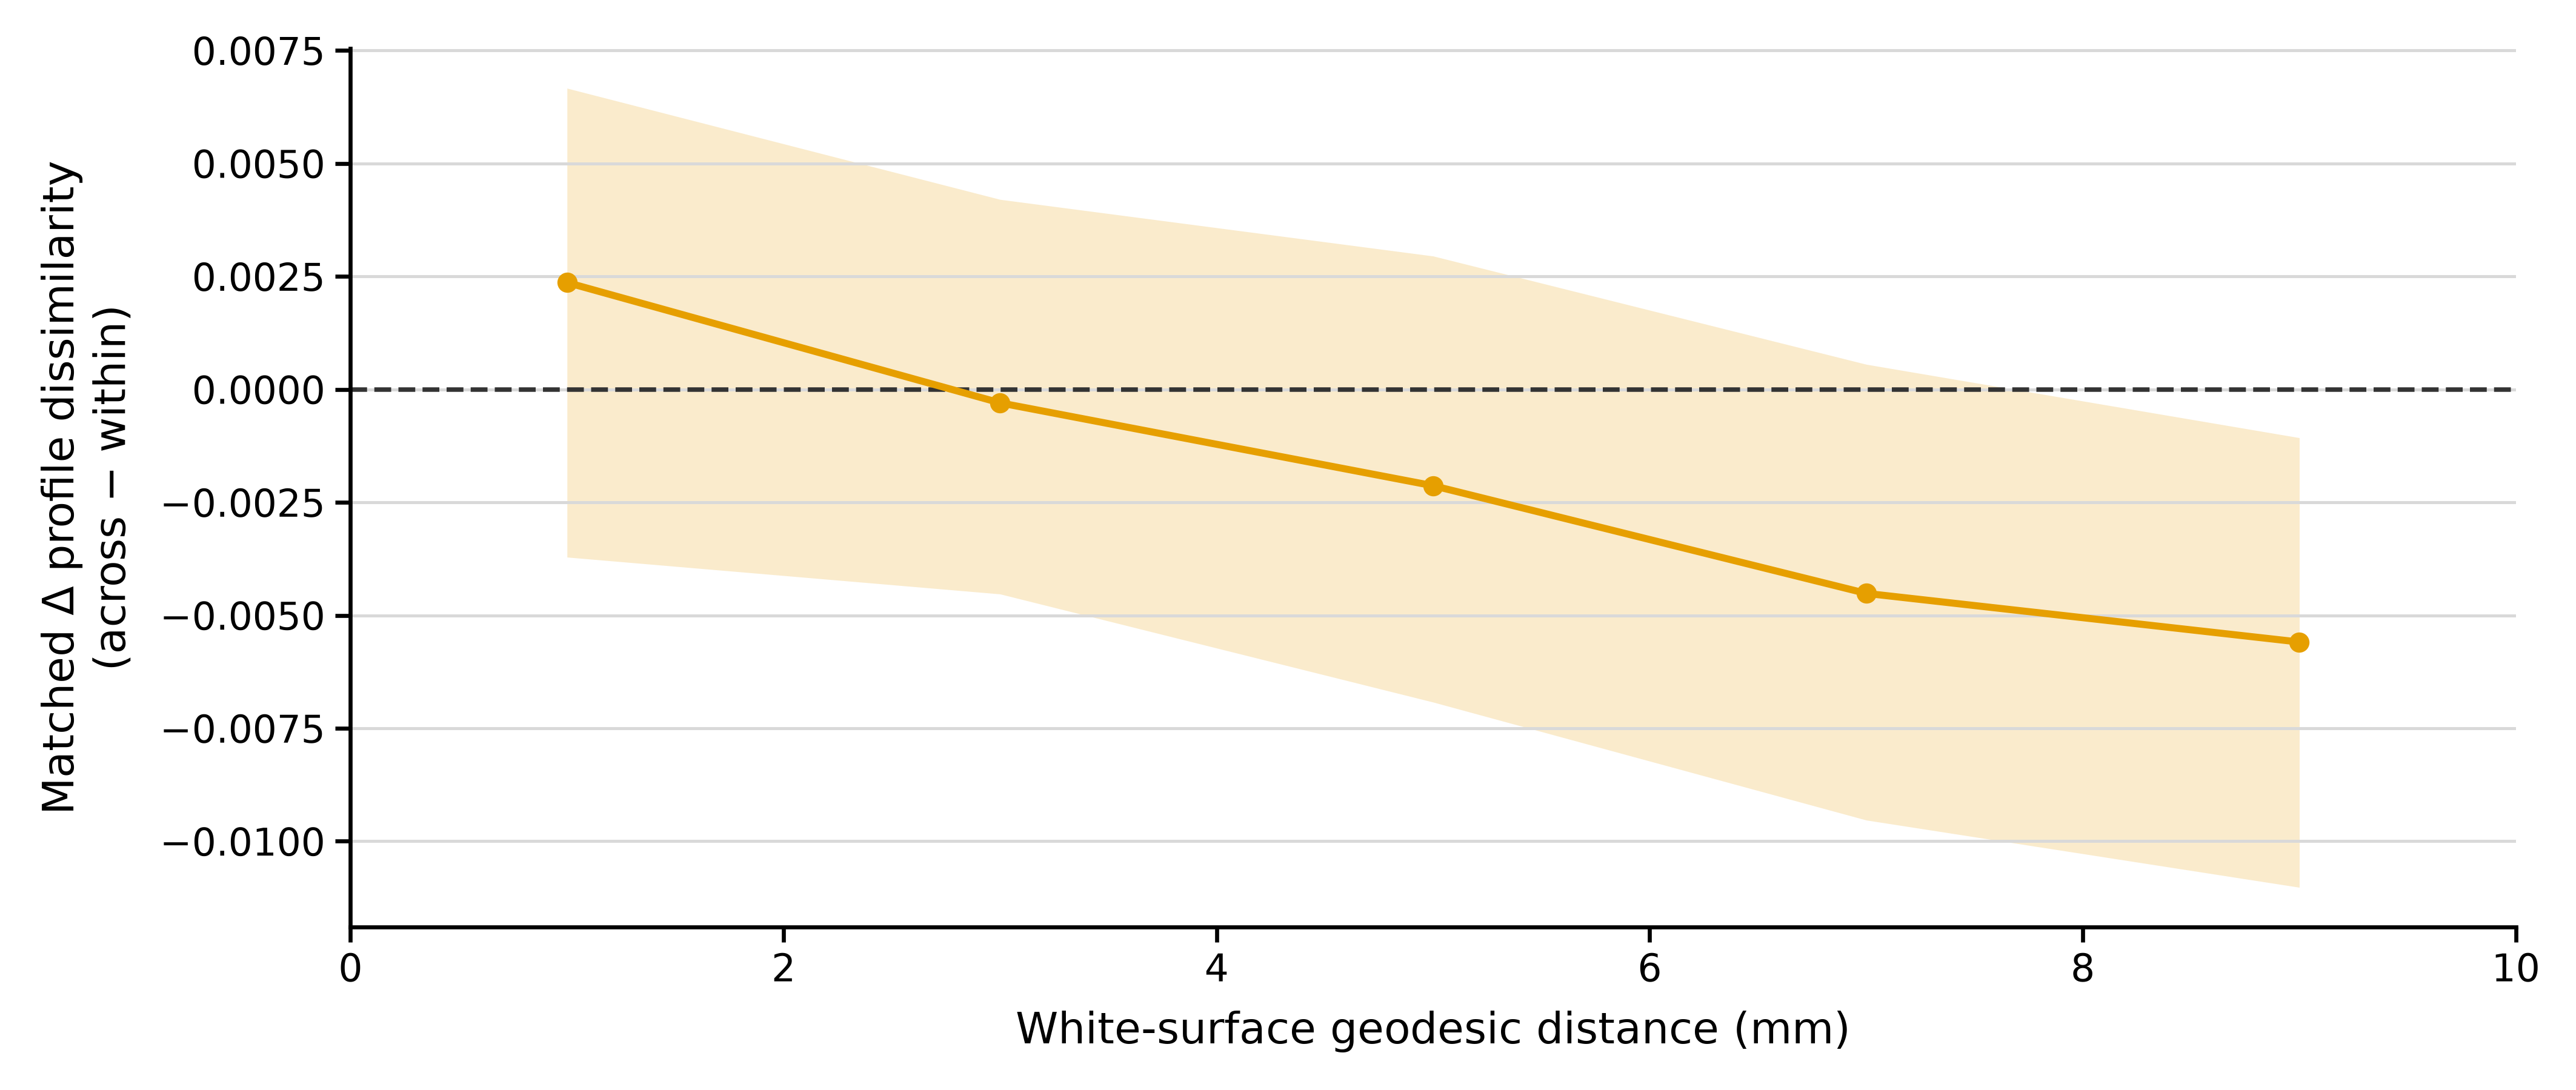

In [7]:
boundary_status = json.loads((BOUNDARY_DIR / 'figure4D_status.json').read_text())
boundary_group = pd.read_csv(BOUNDARY_DIR / 'figure4D_group_summary.csv')
boundary_scalar = pd.read_csv(BOUNDARY_DIR / 'figure4D_0_10_group_summary.csv')
boundary_qc = pd.read_csv(BOUNDARY_DIR / 'figure4D_group_pair_qc_by_bin.csv')
display(pd.DataFrame([boundary_status['pair_qc']]))
display(boundary_group)
display(boundary_scalar)
display(boundary_qc)
assert boundary_status['status'] == 'complete'
assert boundary_status['subjects'] == 325
assert boundary_status['pair_qc']['status'] == 'pass'
show_image(BOUNDARY_DIR / 'Figure4D_boundary_matched_0_10.png')

## Legacy versus formal frozen analysis

This table is a robustness comparison only. Because anchor density, pair scope, $K$, and null seeds changed together, differences cannot be uniquely attributed to any single design change.

In [8]:
comparison = pd.read_csv(COMPARISON_DIR / 'figure4_legacy_vs_formal_comparison.csv')
display(comparison)

,version,anchor,pair_scope,k,delta_L_0_2_mm,auc_0_10_mm_median,auc_0_10_mm_q25,auc_0_10_mm_q75,lambda_median_mm,lambda_q25_mm,lambda_q75_mm
0,Legacy analysis,"2,048 sampled anchors per hemisphere",all valid cortical candidates,20,0.071055,0.357061,0.292378,0.438436,2.660748,2.488761,2.840531
1,Formal frozen analysis,"18,742 bilateral official ico5 anchors",within-DK-region candidates,15,0.069317,0.356685,0.306387,0.429263,2.858480,2.667693,3.041678
